<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/2_quantum/topics_in_qm/aqm_ch08_figures.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*Topics in Quantum Mechanics* — `aqm_ch08_figures.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# AQM Chapter 8 — Figures
**Atoms in Electromagnetic Fields**

| Fig | Content |
|-----|---------|
| 8.1 | Fermi's Golden Rule: sinc² resonance peak |
| 8.2 | Exponential decay & Lorentzian natural linewidth |
| 8.3 | Rabi oscillations: on- and off-resonance |
| 8.4 | Bloch sphere trajectories (π-pulse, π/2-pulse, off-resonance) |
| 8.5 | Jaynes–Cummings collapse and revival |
| 8.6 | AC Stark shift vs detuning; optical dipole trap potential |
| 8.7 | Radiation pressure force vs velocity (Doppler cooling) |
| 8.8 | MOT schematic (capture from text recommended) |

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyArrowPatch, Circle
from mpl_toolkits.mplot3d import Axes3D
import os, zipfile

# ── Dark theme matching aqm_slides.css ────────────────────────
BG     = '#1e1e2e'
FG     = '#cdd6f4'
EDGE   = '#45475a'
BLUE   = '#7ec8e3'
YELLOW = '#f9c74f'
GREEN  = '#90ee90'
RED    = '#e07070'
PURPLE = '#c792ea'
ORANGE = '#ffb347'

plt.rcParams.update({
    'figure.facecolor' : BG,
    'axes.facecolor'   : BG,
    'text.color'       : FG,
    'axes.labelcolor'  : FG,
    'xtick.color'      : FG,
    'ytick.color'      : FG,
    'axes.edgecolor'   : EDGE,
    'grid.color'       : EDGE,
    'grid.alpha'       : 0.30,
    'font.family'      : 'DejaVu Sans',
    'font.size'        : 13,
    'axes.titlesize'   : 14,
    'axes.titleweight' : 'bold',
    'axes.titlecolor'  : BLUE,
    'legend.framealpha': 0.3,
    'legend.edgecolor' : EDGE,
})

OUTDIR = 'figures/ch08'
os.makedirs(OUTDIR, exist_ok=True)

def save(name):
    plt.savefig(f'{OUTDIR}/{name}', dpi=180,
                bbox_inches='tight', facecolor=BG)
    plt.show()
    print(f'  saved → {OUTDIR}/{name}')

print('Setup complete.')

Setup complete.


## Figure 8.1 — Fermi's Golden Rule: sinc² Resonance Peak
**Physics**: $P_{i\to f}(t) \propto t^2\,\mathrm{sinc}^2\!\bigl(\tfrac{(\omega-\omega_{fi})t}{2}\bigr)$.
As $t\to\infty$ the peak narrows and heightens, approaching a $\delta$-function — Fermi's Golden Rule.

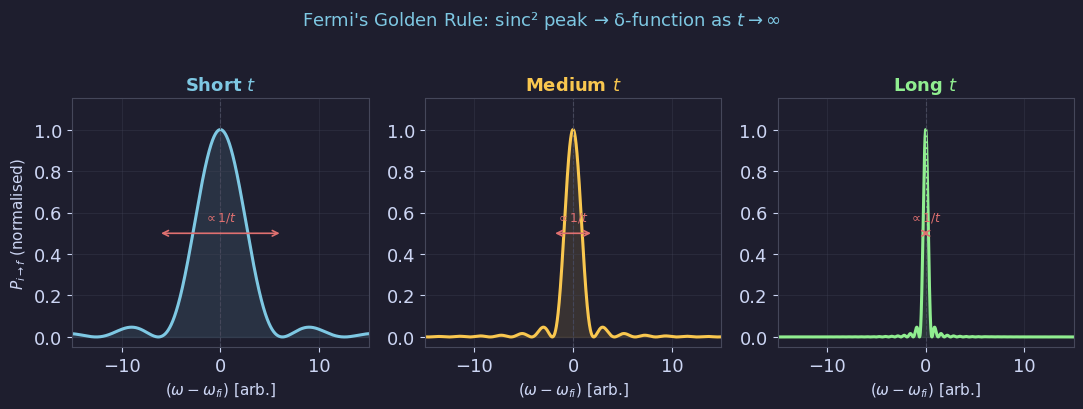

  saved → figures/ch08/fig01_fermis_golden_rule.png


In [2]:
fig, axes = plt.subplots(1, 3, figsize=(11, 4), sharey=False)
fig.patch.set_facecolor(BG)

detuning = np.linspace(-15, 15, 2000)  # (ω - ω_fi) in units of 2π/t_short

def sinc2_prob(delta_omega, t):
    """Transition probability ∝ t² sinc²(δω·t/2)."""
    x = delta_omega * t / 2
    return t**2 * np.sinc(x / np.pi)**2  # np.sinc uses sinc(x)=sin(πx)/(πx)

times   = [1.0, 3.0, 10.0]
colors  = [BLUE, YELLOW, GREEN]
labels  = ['Short $t$', 'Medium $t$', 'Long $t$']

for ax, t, color, label in zip(axes, times, colors, labels):
    P = sinc2_prob(detuning, t)
    P_norm = P / P.max()  # normalise for visibility
    ax.plot(detuning, P_norm, color=color, lw=2.2)
    ax.fill_between(detuning, 0, P_norm, color=color, alpha=0.12)
    ax.set_title(label, color=color, fontsize=13)
    ax.set_xlabel(r'$(\omega-\omega_{fi})$ [arb.]', fontsize=11)
    ax.set_xlim(-15, 15)
    ax.set_ylim(-0.05, 1.15)
    ax.axvline(0, color=EDGE, lw=0.8, ls='--')
    ax.grid(True)
    # FWHM annotation
    fwhm = 2 * np.pi * 2 / t  # approximate FWHM = 4π/t
    ax.annotate('', xy=(fwhm/2, 0.5), xytext=(-fwhm/2, 0.5),
                arrowprops=dict(arrowstyle='<->', color=RED, lw=1.2,
                                mutation_scale=10))
    ax.text(0, 0.56, r'$\propto 1/t$', color=RED,
            ha='center', fontsize=9)

axes[0].set_ylabel(r'$P_{i\to f}$ (normalised)', fontsize=11)
fig.suptitle("Fermi's Golden Rule: sinc² peak → δ-function as $t\\to\\infty$",
             color=BLUE, fontsize=13, y=1.02)
plt.tight_layout(pad=1.0)
save('fig01_fermis_golden_rule.png')

## Figure 8.2 — Exponential Decay and Lorentzian Natural Linewidth
**Physics**: excited-state population $N_2(t) = e^{-\Gamma t}$; Fourier transform gives Lorentzian linewidth $\Gamma = 1/\tau$.

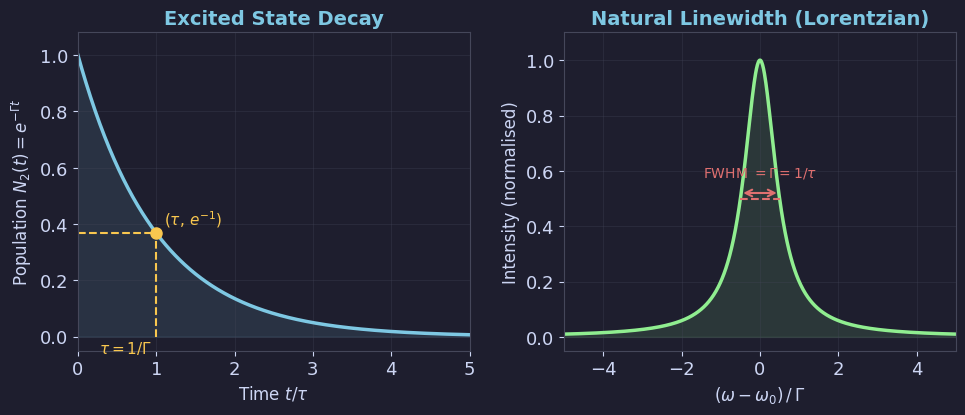

  saved → figures/ch08/fig02_decay_linewidth.png


In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4.5))
fig.patch.set_facecolor(BG)

# ── Left: exponential decay ───────────────────────────────────
t = np.linspace(0, 5, 500)
Gamma = 1.0  # decay rate (τ = 1)
N2 = np.exp(-Gamma * t)

ax1.plot(t, N2, color=BLUE, lw=2.5)
ax1.fill_between(t, 0, N2, color=BLUE, alpha=0.12)

# τ annotation
tau = 1.0 / Gamma
ax1.vlines(tau, 0, np.exp(-1), colors=YELLOW, lw=1.5, ls='--')
ax1.hlines(np.exp(-1), 0, tau, colors=YELLOW, lw=1.5, ls='--')
ax1.plot(tau, np.exp(-1), 'o', color=YELLOW, ms=8)
ax1.text(tau + 0.1, np.exp(-1) + 0.03,
         r'$(\tau,\, e^{-1})$', color=YELLOW, fontsize=11)
ax1.text(tau - 0.05, -0.06, r'$\tau = 1/\Gamma$',
         color=YELLOW, fontsize=11, ha='right')

ax1.set_xlabel(r'Time $t / \tau$', fontsize=12)
ax1.set_ylabel(r'Population $N_2(t) = e^{-\Gamma t}$', fontsize=12)
ax1.set_title('Excited State Decay', color=BLUE)
ax1.set_xlim(0, 5)
ax1.set_ylim(-0.05, 1.08)
ax1.grid(True)

# ── Right: Lorentzian natural linewidth ───────────────────────
omega = np.linspace(-6, 6, 1000)  # (ω - ω₀) in units of Γ
Gamma_L = 1.0
Lorentzian = (Gamma_L / 2) / (omega**2 + (Gamma_L / 2)**2) / np.pi
Lorentzian /= Lorentzian.max()  # normalise to 1

ax2.plot(omega, Lorentzian, color=GREEN, lw=2.5)
ax2.fill_between(omega, 0, Lorentzian, color=GREEN, alpha=0.12)

# FWHM
half_idx = np.where(Lorentzian >= 0.5)[0]
ax2.hlines(0.5, omega[half_idx[0]], omega[half_idx[-1]],
           colors=RED, lw=1.5, ls='--')
ax2.annotate('', xy=(Gamma_L / 2, 0.52),
             xytext=(-Gamma_L / 2, 0.52),
             arrowprops=dict(arrowstyle='<->', color=RED,
                             lw=1.5, mutation_scale=12))
ax2.text(0, 0.58, r'FWHM $= \Gamma = 1/\tau$',
         color=RED, ha='center', fontsize=10)

ax2.set_xlabel(r'$(\omega - \omega_0)\,/\,\Gamma$', fontsize=12)
ax2.set_ylabel(r'Intensity (normalised)', fontsize=12)
ax2.set_title('Natural Linewidth (Lorentzian)', color=BLUE)
ax2.set_xlim(-5, 5)
ax2.set_ylim(-0.05, 1.1)
ax2.grid(True)

plt.tight_layout(pad=1.5)
save('fig02_decay_linewidth.png')

## Figure 8.3 — Rabi Oscillations
**Physics**: $P_2(t) = (\Omega_R/\tilde\Omega)^2\sin^2(\tilde\Omega t/2)$, $\tilde\Omega=\sqrt{\Omega_R^2+\delta^2}$.  
On resonance ($\delta=0$): complete oscillation between $|1\rangle$ and $|2\rangle$.

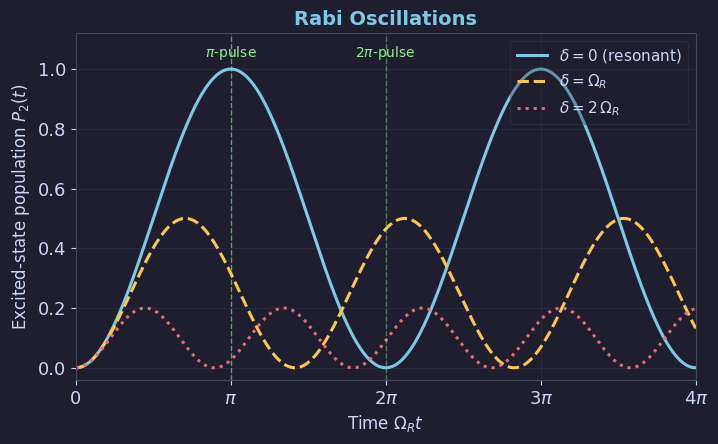

  saved → figures/ch08/fig03_rabi_oscillations.png


In [4]:
fig, ax = plt.subplots(figsize=(8, 4.5))
fig.patch.set_facecolor(BG)

t = np.linspace(0, 4 * np.pi, 1000)  # time in units of 1/Ω_R
Omega_R = 1.0

cases = [
    (0.0,       BLUE,   r'$\delta = 0$ (resonant)',    '-'),
    (Omega_R,   YELLOW, r'$\delta = \Omega_R$',         '--'),
    (2*Omega_R, RED,    r'$\delta = 2\,\Omega_R$',      ':'),
]

for delta, color, label, ls in cases:
    Omega_tilde = np.sqrt(Omega_R**2 + delta**2)
    P2 = (Omega_R / Omega_tilde)**2 * np.sin(Omega_tilde * t / 2)**2
    ax.plot(t, P2, color=color, lw=2.2, ls=ls, label=label)

# π-pulse and 2π-pulse markers
ax.axvline(np.pi, color=GREEN, lw=1.0, ls='--', alpha=0.6)
ax.axvline(2*np.pi, color=GREEN, lw=1.0, ls='--', alpha=0.4)
ax.text(np.pi, 1.04, r'$\pi$-pulse', color=GREEN,
        ha='center', fontsize=10)
ax.text(2*np.pi, 1.04, r'$2\pi$-pulse', color=GREEN,
        ha='center', fontsize=10)

ax.set_xlabel(r'Time $\Omega_R t$', fontsize=12)
ax.set_ylabel(r'Excited-state population $P_2(t)$', fontsize=12)
ax.set_title('Rabi Oscillations', color=BLUE)
ax.set_xlim(0, 4 * np.pi)
ax.set_ylim(-0.04, 1.12)
ax.set_xticks([0, np.pi, 2*np.pi, 3*np.pi, 4*np.pi],
              ['0', r'$\pi$', r'$2\pi$', r'$3\pi$', r'$4\pi$'])
ax.legend(fontsize=11, labelcolor=FG, loc='upper right')
ax.grid(True)

save('fig03_rabi_oscillations.png')

## Figure 8.4 — Bloch Sphere Trajectories
**Physics**: state vector $\mathbf{r}_{\rm Bloch}$ precesses about $\mathbf{\Omega}_{\rm eff} = (-\Omega_R, 0, \delta)$.  
On resonance: rotation about $\hat{x}$. North pole = $|2\rangle$, south pole = $|1\rangle$.

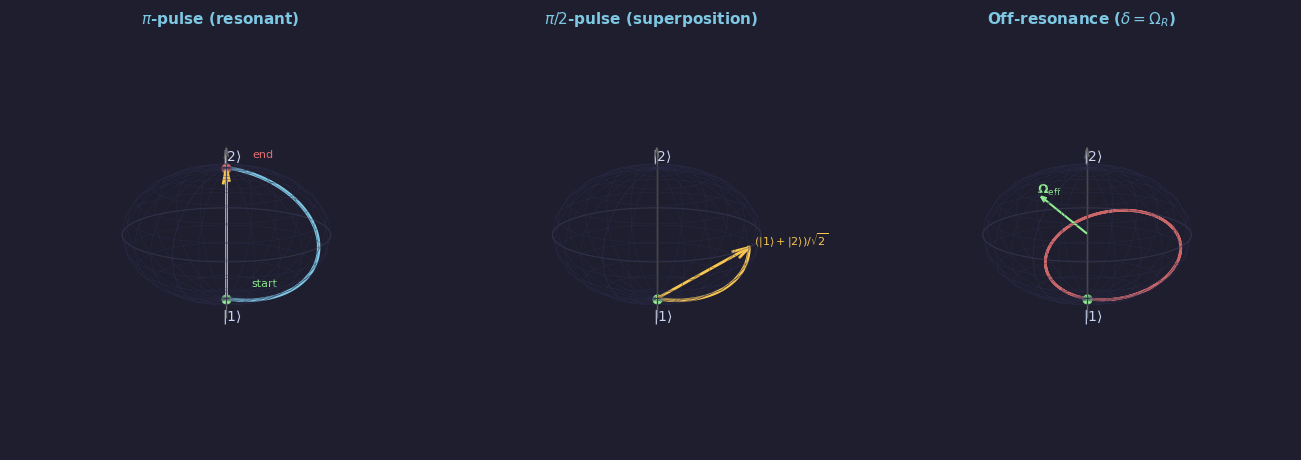

  saved → figures/ch08/fig04_bloch_sphere.png


In [5]:
fig = plt.figure(figsize=(13, 5))
fig.patch.set_facecolor(BG)

def bloch_sphere_ax(fig, pos, title):
    ax = fig.add_subplot(pos, projection='3d')
    ax.set_facecolor(BG)
    # Sparse wireframe
    u = np.linspace(0, 2*np.pi, 25)
    v = np.linspace(0, np.pi, 13)
    xs = np.outer(np.cos(u), np.sin(v))
    ys = np.outer(np.sin(u), np.sin(v))
    zs = np.outer(np.ones(25), np.cos(v))
    ax.plot_wireframe(xs, ys, zs, color='#2d2d4e', lw=0.4, alpha=0.6)
    # Equator
    eq = np.linspace(0, 2*np.pi, 100)
    ax.plot(np.cos(eq), np.sin(eq), 0, color=EDGE, lw=0.8, alpha=0.5)
    # z-axis
    ax.quiver(0, 0, -1.3, 0, 0, 2.6, color='#666', lw=1.0,
              arrow_length_ratio=0.06)
    # Pole labels
    ax.text(0.08, 0, 1.15, r'$|2\rangle$', color=FG, fontsize=10)
    ax.text(0.08, 0, -1.30, r'$|1\rangle$', color=FG, fontsize=10)
    ax.set_xlim(-1.3, 1.3)
    ax.set_ylim(-1.3, 1.3)
    ax.set_zlim(-1.5, 1.5)
    ax.set_axis_off()
    ax.set_title(title, color=BLUE, fontsize=11, pad=4)
    return ax

# ── Panel 1: π-pulse (resonant, δ=0) ─────────────────────────
ax1 = bloch_sphere_ax(fig, 131, r'$\pi$-pulse (resonant)')
t_pi = np.linspace(0, np.pi, 100)
# Rotation about x-axis: (0,0,-1) → (0,0,+1)
traj_x = np.zeros_like(t_pi)
traj_y = np.sin(t_pi)
traj_z = -np.cos(t_pi)
ax1.plot(traj_x, traj_y, traj_z, color=BLUE, lw=2.5)
ax1.quiver(0,0,-1, 0,0,2, color=YELLOW, lw=2, arrow_length_ratio=0.12)
ax1.scatter([0],[0],[-1], color=GREEN, s=40, zorder=5)  # start
ax1.scatter([0],[0],[1],  color=RED,   s=40, zorder=5)  # end
ax1.text(-0.5, 0, -1.0, 'start', color=GREEN, fontsize=8)
ax1.text(-0.5, 0,  1.0, 'end',   color=RED,   fontsize=8)
ax1.view_init(elev=15, azim=30)

# ── Panel 2: π/2-pulse (resonant) ────────────────────────────
ax2 = bloch_sphere_ax(fig, 132, r'$\pi/2$-pulse (superposition)')
t_pi2 = np.linspace(0, np.pi/2, 80)
traj_x2 = np.zeros_like(t_pi2)
traj_y2 = np.sin(t_pi2)
traj_z2 = -np.cos(t_pi2)
ax2.plot(traj_x2, traj_y2, traj_z2, color=YELLOW, lw=2.5)
ax2.quiver(0,0,-1, 0,traj_y2[-1],1+traj_z2[-1],
           color=YELLOW, lw=2, arrow_length_ratio=0.15)
ax2.scatter([0],[0],[-1], color=GREEN, s=40, zorder=5)
ax2.text(0.1, traj_y2[-1]+0.1, traj_z2[-1]+0.1,
         r'$(|1\rangle+|2\rangle)/\sqrt{2}$', color=YELLOW, fontsize=8)
ax2.view_init(elev=15, azim=30)

# ── Panel 3: off-resonance (δ = Ω_R) ─────────────────────────
ax3 = bloch_sphere_ax(fig, 133, r'Off-resonance ($\delta = \Omega_R$)')
Omega_R = 1.0
delta   = 1.0
Omega_eff = np.sqrt(Omega_R**2 + delta**2)
theta_tilt = np.arctan2(Omega_R, delta)  # tilt from z-axis

t_off = np.linspace(0, 2*np.pi / Omega_eff * 2, 300)
# Rotation about tilted axis n̂ = (sin θ, 0, cos θ) [but ΩR along x, δ along z]
# Effective field: Ω_eff = (Ω_R, 0, δ) → n̂ = (Ω_R, 0, δ)/Ω_eff
nx, ny, nz = Omega_R/Omega_eff, 0, delta/Omega_eff

def rotate_about(n, v, theta):
    """Rodrigues formula: rotate vector v by angle theta about unit vector n."""
    nx,ny,nz = n
    vx,vy,vz = v
    c,s = np.cos(theta), np.sin(theta)
    dot = nx*vx + ny*vy + nz*vz
    cross = (ny*vz-nz*vy, nz*vx-nx*vz, nx*vy-ny*vx)
    return (c*vx+(1-c)*dot*nx+s*cross[0],
            c*vy+(1-c)*dot*ny+s*cross[1],
            c*vz+(1-c)*dot*nz+s*cross[2])

v0 = (0, 0, -1)  # start at south pole
traj_off = np.array([rotate_about((nx,ny,nz), v0, Omega_eff*ti)
                     for ti in t_off])
ax3.plot(traj_off[:,0], traj_off[:,1], traj_off[:,2],
         color=RED, lw=2.0, alpha=0.9)
# Effective field axis
ax3.quiver(0,0,0, nx*1.2, ny*1.2, nz*1.2,
           color=GREEN, lw=1.5, arrow_length_ratio=0.1)
ax3.text(nx*1.3, ny*1.3, nz*1.3,
         r'$\mathbf{\Omega}_{\rm eff}$', color=GREEN, fontsize=9)
ax3.scatter(*v0, color=GREEN, s=40, zorder=5)
ax3.view_init(elev=15, azim=30)

plt.tight_layout(pad=0.5)
save('fig04_bloch_sphere.png')

## Figure 8.5 — Jaynes–Cummings Collapse and Revival
**Physics**: atom starts in $|e\rangle$, field in coherent state $|\alpha\rangle$ with $\bar{n}=|\alpha|^2$ photons.  
$$P_e(t) = \frac{1}{2}\left[1 + e^{-\bar{n}}\sum_{n=0}^\infty \frac{\bar{n}^n}{n!}\cos(2g\sqrt{n+1}\,t)\right]$$
Collapse at $t_c \sim 1/(g)$; revival at $t_r \sim 2\pi\sqrt{\bar{n}}/g$.

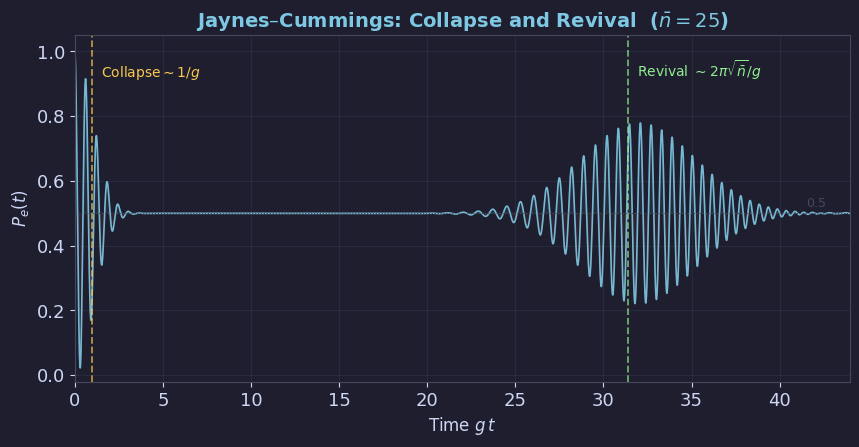

  saved → figures/ch08/fig05_JC_collapse_revival.png


In [6]:
fig, ax = plt.subplots(figsize=(10, 4.5))
fig.patch.set_facecolor(BG)

n_bar = 25.0    # mean photon number
g     = 1.0     # coupling constant (units: g=1)
t_max = 2 * np.pi * np.sqrt(n_bar) / g * 1.4  # show ~1.4 revival periods
t     = np.linspace(0, t_max, 4000)

# Coherent state Poisson weights
n_max = int(n_bar + 8 * np.sqrt(n_bar))  # truncate sum
ns    = np.arange(0, n_max + 1)

# P_e(t) = 0.5 * [1 + Σ_n P(n) cos(2g√(n+1) t)]
log_weights = ns * np.log(n_bar) - n_bar - np.array(
    [sum(np.log(np.arange(1, k+1))) if k > 0 else 0 for k in ns])
weights = np.exp(log_weights)  # = n_bar^n * e^{-n_bar} / n!

Pe = np.zeros_like(t)
for n, w in zip(ns, weights):
    Pe += w * np.cos(2 * g * np.sqrt(n + 1) * t)
Pe = 0.5 * (1 + Pe)

ax.plot(t, Pe, color=BLUE, lw=1.2, alpha=0.9)
ax.fill_between(t, 0.5, Pe, where=Pe>0.5, color=BLUE, alpha=0.08)
ax.fill_between(t, Pe, 0.5, where=Pe<0.5, color=RED,  alpha=0.08)

# Annotations
t_collapse = 1.0 / g
t_revival  = 2 * np.pi * np.sqrt(n_bar) / g

ax.axvline(t_collapse, color=YELLOW, lw=1.3, ls='--', alpha=0.7)
ax.text(t_collapse + 0.5, 0.92,
        r'Collapse$\sim 1/g$', color=YELLOW, fontsize=10)

ax.axvline(t_revival, color=GREEN, lw=1.3, ls='--', alpha=0.7)
ax.text(t_revival + 0.5, 0.92,
        r'Revival $\sim 2\pi\sqrt{\bar{n}}/g$', color=GREEN, fontsize=10)

ax.axhline(0.5, color=EDGE, lw=0.8, ls=':')
ax.text(t_max * 0.97, 0.52, '0.5', color=EDGE, fontsize=9, ha='right')

ax.set_xlabel(r'Time $g\,t$', fontsize=12)
ax.set_ylabel(r'$P_e(t)$', fontsize=12)
ax.set_title(
    r'Jaynes–Cummings: Collapse and Revival  ($\bar{n} = 25$)',
    color=BLUE)
ax.set_xlim(0, t_max)
ax.set_ylim(-0.02, 1.05)
ax.grid(True)

save('fig05_JC_collapse_revival.png')

## Figure 8.6 — AC Stark Shift and Optical Dipole Trap
**Physics**: $\Delta E_g = -\hbar\Omega_R^2/(4\delta)$, $\Delta E_e = +\hbar\Omega_R^2/(4\delta)$.  
For red detuning ($\delta < 0$): ground state drawn toward intensity maximum → dipole trap.

<>:18: SyntaxWarning: invalid escape sequence '\d'
<>:20: SyntaxWarning: invalid escape sequence '\d'
<>:18: SyntaxWarning: invalid escape sequence '\d'
<>:20: SyntaxWarning: invalid escape sequence '\d'
/tmp/ipykernel_2828/2112800178.py:18: SyntaxWarning: invalid escape sequence '\d'
  color=RED, alpha=0.05, label='Red detuned ($\delta<0$)')
/tmp/ipykernel_2828/2112800178.py:20: SyntaxWarning: invalid escape sequence '\d'
  color=BLUE, alpha=0.05, label='Blue detuned ($\delta>0$)')


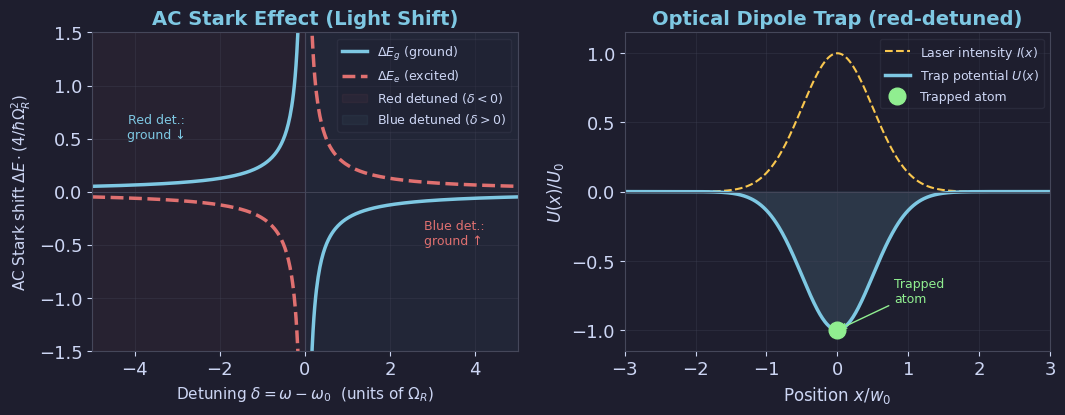

  saved → figures/ch08/fig06_AC_stark_dipole_trap.png


In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))
fig.patch.set_facecolor(BG)

# ── Left: AC Stark shift vs detuning ──────────────────────────
Omega_R = 1.0
delta = np.linspace(-5, 5, 500)
delta_nonzero = np.where(np.abs(delta) < 0.05, np.nan, delta)

dE_g = -Omega_R**2 / (4 * delta_nonzero)
dE_e = +Omega_R**2 / (4 * delta_nonzero)

ax1.plot(delta, dE_g, color=BLUE,   lw=2.5, label=r'$\Delta E_g$ (ground)')
ax1.plot(delta, dE_e, color=RED,    lw=2.5, label=r'$\Delta E_e$ (excited)',
         ls='--')
ax1.axvline(0, color=EDGE, lw=0.8)
ax1.axhline(0, color=EDGE, lw=0.6)
ax1.fill_betweenx(np.linspace(-1.5, 1.5, 10), -5, 0,
                  color=RED, alpha=0.05, label='Red detuned ($\delta<0$)')
ax1.fill_betweenx(np.linspace(-1.5, 1.5, 10), 0, 5,
                  color=BLUE, alpha=0.05, label='Blue detuned ($\delta>0$)')

ax1.text(-3.5,  0.5, 'Red det.:\nground ↓', color=BLUE, fontsize=9, ha='center')
ax1.text( 3.5, -0.5, 'Blue det.:\nground ↑', color=RED,  fontsize=9, ha='center')

ax1.set_xlabel(r'Detuning $\delta = \omega - \omega_0$  (units of $\Omega_R$)',
               fontsize=11)
ax1.set_ylabel(r'AC Stark shift $\Delta E \cdot (4/\hbar\Omega_R^2)$', fontsize=11)
ax1.set_title('AC Stark Effect (Light Shift)', color=BLUE)
ax1.set_xlim(-5, 5)
ax1.set_ylim(-1.5, 1.5)
ax1.legend(fontsize=9, labelcolor=FG)
ax1.grid(True)

# ── Right: optical dipole trap potential ──────────────────────
x = np.linspace(-3, 3, 500)  # position (units of beam waist w₀)
# Gaussian intensity profile I(x) ∝ exp(-2x²/w₀²)
I_x = np.exp(-2 * x**2)
# Red-detuned: U(x) ∝ -I(x) → trapping potential for ground state
U_trap = -I_x  # in units of U_0 = ℏΩ_R²/4|δ|

ax2.plot(x, I_x,    color=YELLOW, lw=1.5, ls='--', label='Laser intensity $I(x)$')
ax2.plot(x, U_trap, color=BLUE,   lw=2.5,           label='Trap potential $U(x)$')
ax2.fill_between(x, U_trap, 0, color=BLUE, alpha=0.15)

ax2.axhline(0, color=EDGE, lw=0.6)

# Atom at bottom of trap
ax2.plot(0, -1.0, 'o', color=GREEN, ms=12, zorder=5, label='Trapped atom')
ax2.annotate('Trapped\natom', xy=(0, -1.0), xytext=(0.8, -0.8),
             color=GREEN, fontsize=9,
             arrowprops=dict(arrowstyle='->', color=GREEN, lw=1.0))

ax2.set_xlabel(r'Position $x / w_0$', fontsize=12)
ax2.set_ylabel(r'$U(x) / U_0$', fontsize=12)
ax2.set_title('Optical Dipole Trap (red-detuned)', color=BLUE)
ax2.set_xlim(-3, 3)
ax2.set_ylim(-1.15, 1.15)
ax2.legend(fontsize=9, labelcolor=FG)
ax2.grid(True)

plt.tight_layout(pad=1.5)
save('fig06_AC_stark_dipole_trap.png')

## Figure 8.7 — Radiation Pressure Force (Doppler Cooling)
**Physics**: scattering force $F(v) \propto \Gamma\rho_{22}(v)$ where the Lorentzian depends on
Doppler-shifted detuning $\delta_v = \delta + kv$.  
Two counter-propagating beams: net force is velocity-dependent friction.

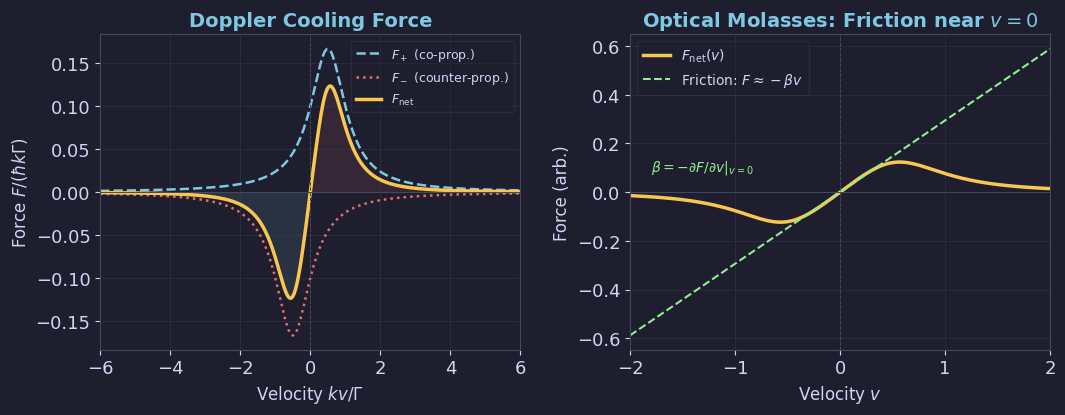

  saved → figures/ch08/fig07_doppler_cooling.png


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
fig.patch.set_facecolor(BG)

Gamma   = 1.0
delta   = -0.5    # optimal red detuning: δ = -Γ/2
Omega_R = 0.5
k       = 1.0

def rho22(delta_eff):
    s0 = 2 * Omega_R**2 / Gamma**2
    return 0.5 * s0 / (1 + s0 + (2 * delta_eff / Gamma)**2)

v = np.linspace(-6, 6, 1000)

# ── Left: single-beam and two-beam force ──────────────────────
ax = axes[0]
F_plus  = k * rho22(delta + k * v)    # ← 수정: +hbar_k 제거
F_minus = -k * rho22(delta - k * v)
F_net   = F_plus + F_minus

ax.plot(v, F_plus,  color=BLUE,   lw=1.8, ls='--',
        label=r'$F_+$ (co-prop.)')
ax.plot(v, F_minus, color=RED,    lw=1.8, ls=':',
        label=r'$F_-$ (counter-prop.)')
ax.plot(v, F_net,   color=YELLOW, lw=2.5,
        label=r'$F_{\rm net}$')
ax.fill_between(v, F_net, 0, where=F_net < 0, color=BLUE, alpha=0.12)
ax.fill_between(v, F_net, 0, where=F_net > 0, color=RED,  alpha=0.12)
ax.axhline(0, color=EDGE, lw=0.7)
ax.axvline(0, color=EDGE, lw=0.7, ls='--')
ax.set_xlabel(r'Velocity $kv/\Gamma$', fontsize=12)
ax.set_ylabel(r'Force $F/(\hbar k \Gamma)$', fontsize=12)
ax.set_title('Doppler Cooling Force', color=BLUE)
ax.legend(fontsize=9, labelcolor=FG)
ax.grid(True)
ax.set_xlim(-6, 6)

# ── Right: friction coefficient near v = 0 ────────────────────
ax2 = axes[1]
v_lin  = np.linspace(-2, 2, 500)
F_net2 = k * rho22(delta + k * v_lin) - k * rho22(delta - k * v_lin)

beta_idx = np.abs(v_lin) < 0.4
beta_fit = np.polyfit(v_lin[beta_idx], F_net2[beta_idx], 1)
F_linear = np.polyval(beta_fit, v_lin)

ax2.plot(v_lin, F_net2,   color=YELLOW, lw=2.5, label=r'$F_{\rm net}(v)$')
ax2.plot(v_lin, F_linear, color=GREEN,  lw=1.5, ls='--',
         label=r'Friction: $F \approx -\beta v$')
ax2.axhline(0, color=EDGE, lw=0.7)
ax2.axvline(0, color=EDGE, lw=0.7, ls='--')
ax2.text(-1.8, F_net2.max() * 0.7,
         r'$\beta = -\partial F/\partial v|_{v=0}$',
         color=GREEN, fontsize=10)
ax2.set_xlabel(r'Velocity $v$', fontsize=12)
ax2.set_ylabel(r'Force (arb.)', fontsize=12)
ax2.set_title(r'Optical Molasses: Friction near $v=0$', color=BLUE)
ax2.legend(fontsize=10, labelcolor=FG)
ax2.grid(True)
ax2.set_xlim(-2, 2)

plt.tight_layout(pad=1.5)
save('fig07_doppler_cooling.png')

## Figure 8.7 — Fix: syntax error correction

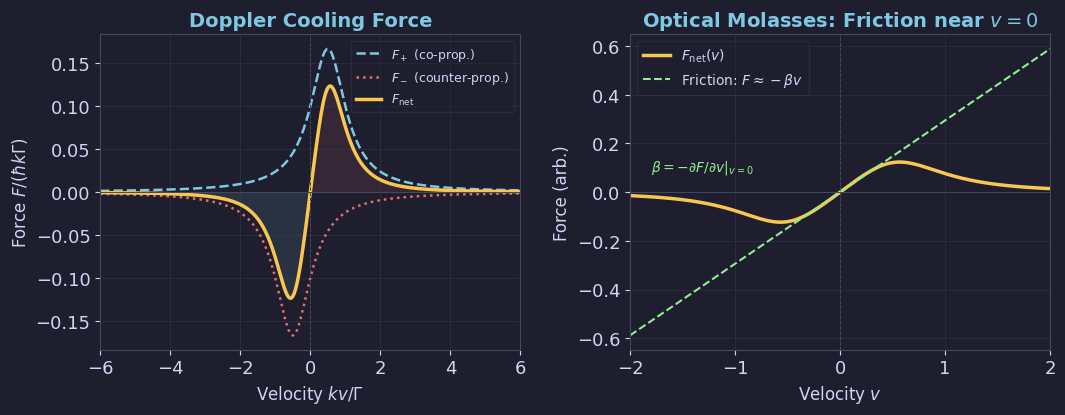

  saved → figures/ch08/fig07_doppler_cooling.png


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
fig.patch.set_facecolor(BG)

Gamma = 1.0
delta = -0.5
Omega_R = 0.5
k = 1.0

def rho22(delta_eff):
    s0 = 2 * Omega_R**2 / Gamma**2
    return 0.5 * s0 / (1 + s0 + (2 * delta_eff / Gamma)**2)

v = np.linspace(-6, 6, 1000)
delta_plus  = delta + k * v
delta_minus = delta - k * v
F_plus  = k * rho22(delta_plus)
F_minus = -k * rho22(delta_minus)
F_net   = F_plus + F_minus

ax = axes[0]
ax.plot(v, F_plus,  color=BLUE,   lw=1.8, ls='--',
        label=r'$F_+$ (co-prop.)')
ax.plot(v, F_minus, color=RED,    lw=1.8, ls=':',
        label=r'$F_-$ (counter-prop.)')
ax.plot(v, F_net,   color=YELLOW, lw=2.5,
        label=r'$F_{\rm net}$')
ax.fill_between(v, F_net, 0, where=F_net<0, color=BLUE, alpha=0.12)
ax.fill_between(v, F_net, 0, where=F_net>0, color=RED,  alpha=0.12)
ax.axhline(0, color=EDGE, lw=0.7)
ax.axvline(0, color=EDGE, lw=0.7, ls='--')
ax.set_xlabel(r'Velocity $kv/\Gamma$', fontsize=12)
ax.set_ylabel(r'Force $F/(\hbar k \Gamma)$', fontsize=12)
ax.set_title('Doppler Cooling Force', color=BLUE)
ax.legend(fontsize=9, labelcolor=FG)
ax.grid(True)
ax.set_xlim(-6, 6)

# Linear regime (friction coefficient)
v_lin = np.linspace(-2, 2, 500)
F_net2 = k*rho22(delta + k*v_lin) - k*rho22(delta - k*v_lin)
beta_idx = np.abs(v_lin) < 0.4
beta_fit = np.polyfit(v_lin[beta_idx], F_net2[beta_idx], 1)
F_linear = np.polyval(beta_fit, v_lin)

ax2 = axes[1]
ax2.plot(v_lin, F_net2,   color=YELLOW, lw=2.5, label=r'$F_{\rm net}(v)$')
ax2.plot(v_lin, F_linear, color=GREEN,  lw=1.5, ls='--',
         label=r'Friction: $F \approx -\beta v$')
ax2.axhline(0, color=EDGE, lw=0.7)
ax2.axvline(0, color=EDGE, lw=0.7, ls='--')
ax2.text(-1.8, F_net2.max()*0.7,
         r'$\beta = -\partial F/\partial v|_{v=0}$', color=GREEN, fontsize=10)
ax2.set_xlabel(r'Velocity $v$', fontsize=12)
ax2.set_ylabel(r'Force (arb.)', fontsize=12)
ax2.set_title(r'Optical Molasses: Friction near $v=0$', color=BLUE)
ax2.legend(fontsize=10, labelcolor=FG)
ax2.grid(True)
ax2.set_xlim(-2, 2)

plt.tight_layout(pad=1.5)
save('fig07_doppler_cooling.png')

## Figure 8.8 — MOT Schematic
This figure is best captured from Tong's notes or Metcalf & van der Straten (Fig. 10.1).  
The cell below generates a simplified schematic diagram.

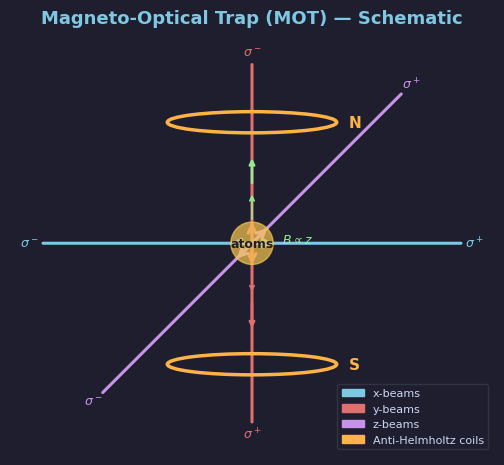

  saved → figures/ch08/fig08_MOT_schematic.png


In [10]:
fig, ax = plt.subplots(figsize=(7, 5.5))
ax.set_facecolor(BG)
fig.patch.set_facecolor(BG)
ax.set_xlim(-4, 4)
ax.set_ylim(-3.5, 3.5)
ax.set_aspect('equal')
ax.axis('off')

# Atom cloud at centre
cloud = plt.Circle((0,0), 0.35, color=YELLOW, alpha=0.7, zorder=5)
ax.add_patch(cloud)
ax.text(0, 0, 'atoms', color=BG, ha='center', va='center',
        fontsize=9, fontweight='bold', zorder=6)

# 6 laser beams (3 pairs)
beam_configs = [
    ((-3.5, 0), (3.5, 0),   BLUE,   r'$\sigma^-$', r'$\sigma^+$'),   # x
    ((0, -3.0), (0, 3.0),   RED,    r'$\sigma^+$', r'$\sigma^-$'),   # y
    ((-2.5,-2.5),(2.5,2.5), PURPLE, r'$\sigma^-$', r'$\sigma^+$'),   # z (diagonal)
]
for (x1,y1),(x2,y2), color, label_start, label_end in beam_configs:
    # Arrow toward centre
    ax.annotate('', xy=(0.4*(x2-x1)/np.hypot(x2-x1,y2-y1),
                        0.4*(y2-y1)/np.hypot(x2-x1,y2-y1)),
                xytext=(x1, y1),
                arrowprops=dict(arrowstyle='->', color=color,
                                lw=2.2, mutation_scale=14))
    ax.annotate('', xy=(-0.4*(x2-x1)/np.hypot(x2-x1,y2-y1),
                        -0.4*(y2-y1)/np.hypot(x2-x1,y2-y1)),
                xytext=(x2, y2),
                arrowprops=dict(arrowstyle='->', color=color,
                                lw=2.2, mutation_scale=14))
    ax.text(x1*1.05, y1*1.05, label_start, color=color,
            ha='center', va='center', fontsize=9)
    ax.text(x2*1.05, y2*1.05, label_end,   color=color,
            ha='center', va='center', fontsize=9)

# Anti-Helmholtz coils (top and bottom, schematic)
for cy, label in [(2.0, 'N'), (-2.0, 'S')]:
    coil = mpatches.Ellipse((0, cy), 2.8, 0.35,
                             edgecolor=ORANGE, facecolor='none',
                             lw=2.5, zorder=3)
    ax.add_patch(coil)
    ax.text(1.6, cy, label, color=ORANGE, fontsize=11,
            fontweight='bold', va='center')

# B-field gradient arrow
for yi in [-1.2, -0.6, 0.6, 1.2]:
    lw_scale = 0.6 + abs(yi)
    color_B = GREEN if yi > 0 else RED
    ax.annotate('', xy=(0, yi + 0.25*np.sign(yi)),
                xytext=(0, yi - 0.25*np.sign(yi)),
                arrowprops=dict(arrowstyle='->', color=color_B,
                                lw=lw_scale, mutation_scale=8))
ax.text(0.5, 0, r'$B\propto z$', color=GREEN, fontsize=9)

ax.set_title('Magneto-Optical Trap (MOT) — Schematic',
             color=BLUE, fontsize=13)

# Legend
legend_elements = [
    mpatches.Patch(color=BLUE,   label='x-beams'),
    mpatches.Patch(color=RED,    label='y-beams'),
    mpatches.Patch(color=PURPLE, label='z-beams'),
    mpatches.Patch(color=ORANGE, label='Anti-Helmholtz coils'),
]
ax.legend(handles=legend_elements, fontsize=8,
          loc='lower right', facecolor=BG,
          labelcolor=FG, framealpha=0.5)

save('fig08_MOT_schematic.png')

## Auto-zip and Download

In [11]:
import zipfile, os
from google.colab import files

zip_name = 'aqm_ch08_figures.zip'
fig_dir  = 'figures/ch08'

with zipfile.ZipFile(zip_name, 'w', zipfile.ZIP_DEFLATED) as zf:
    for fname in sorted(os.listdir(fig_dir)):
        if fname.endswith('.png'):
            fpath = os.path.join(fig_dir, fname)
            zf.write(fpath, arcname=os.path.join('figures', 'ch08', fname))
            print(f'  added: {fname}')

print(f'\nCreated: {zip_name}  ({os.path.getsize(zip_name)/1024:.0f} KB)')
files.download(zip_name)

  added: fig01_fermis_golden_rule.png
  added: fig02_decay_linewidth.png
  added: fig03_rabi_oscillations.png
  added: fig04_bloch_sphere.png
  added: fig05_JC_collapse_revival.png
  added: fig06_AC_stark_dipole_trap.png
  added: fig07_doppler_cooling.png
  added: fig08_MOT_schematic.png

Created: aqm_ch08_figures.zip  (941 KB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
## Figure–Slide Mapping

| File | Slide section | Width |
|------|--------------|-------|
| `fig01_fermis_golden_rule.png` | 8.2 Fermi's Golden Rule | 95% |
| `fig02_decay_linewidth.png` | 8.4 Spontaneous Emission Rate | 92% |
| `fig03_rabi_oscillations.png` | 8.5 Rabi Oscillations | 90% |
| `fig04_bloch_sphere.png` | 8.5 Bloch Sphere | 95% |
| `fig05_JC_collapse_revival.png` | 8.6 Jaynes–Cummings | 90% |
| `fig06_AC_stark_dipole_trap.png` | 8.7 AC Stark Effect | 95% |
| `fig07_doppler_cooling.png` | 8.8 Doppler Cooling | 95% |
| `fig08_MOT_schematic.png` | 8.8 MOT (or use textbook capture) | 75% |